---

### Cabecalho do arquivo

**Disciplina:** Inteligencia Artificial - 7o CC (Turma 7N)
**Projeto:** Coracao em Alerta - Classificacao de Doenca Arterial Coronariana com IA
**Integrante:** Tiago Caspirro Cardoso (RA 10390562)

**Sintese do conteudo do arquivo:** notebook da Parte 2 (N1 - Artigo Parcial) do Projeto de
IA. Executa o levantamento de requisitos de dados, a analise exploratoria (EDA) e a
preparacao do dataset UCI Heart Disease (Cleveland), alem de um protocolo experimental
completo (baseline, validacao cruzada, comparacao de modelos e metricas voltadas a triagem
em saude).

**Historico de alteracoes:**

| Data | Autor | Descricao |
|---|---|---|
| 2026-09-22 | Tiago Caspirro Cardoso | Criacao do notebook: EDA, preparacao dos dados, baseline (Regressao Logistica), comparacao com Random Forest e XGBoost, avaliacao com metricas completas e explicabilidade (SHAP). |
| 2026-09-23 | Tiago Caspirro Cardoso | Revisao pos-autoavaliacao: adicionada analise exploratoria das variaveis categoricas (`cp`, `talassemia`, `exang`) vs. alvo; correcao da proporcao de casos positivos pos-limpeza reportada no artigo (46,1%, nao 45,9%); correcao de vazamento de dados (data leakage) -- a padronizacao do baseline passou a ser feita dentro de um Pipeline, refeita a cada fold da validacao cruzada, em vez de ajustada uma unica vez no treino inteiro antes do CV; adicionada especificidade como metrica de validacao cruzada; blindada a celula do SHAP contra o caso do baseline (nao-arvore) vencer por F1-score. |

---

# Coracao em Alerta: Classificacao de Doenca Arterial Coronariana com IA

**Projeto de IA - Parte 2 (N1) - Artigo Parcial**

**Integrante:** Tiago Caspirro Cardoso (RA 10390562) — Turma 7N

Este notebook documenta a analise exploratoria e a preparacao dos dados do projeto,
seguindo o protocolo experimental definido apos o parecer do professor sobre a Parte 1
da proposta (ver `pontos_de_melhoria_para_projeto_final.md`). O objetivo do projeto e
**classificar a presenca de doenca arterial coronariana** a partir de dados clinicos
transversais — nao se trata de previsao de risco futuro (prognostico longitudinal), pois
o dataset utilizado nao possui acompanhamento no tempo.


## 1. Descricao do dataset

**Nome:** UCI Heart Disease Dataset — subconjunto **Cleveland** (processed.cleveland.data)

**Origem:** Cleveland Clinic Foundation, doado por Robert Detrano, M.D., Ph.D., e
disponibilizado publicamente pelo UCI Machine Learning Repository em 1988.

**Forma de acesso:** download direto, sem necessidade de conta ou aprovacao —
`https://archive.ics.uci.edu/dataset/45/heart+disease` (arquivo `processed.cleveland.data`,
tambem espelhado no Kaggle).

**Licenca:** disponibilizado sob licenca CC BY 4.0 pelo UCI Machine Learning Repository —
uso e redistribuicao permitidos para fins academicos, com atribuicao da fonte.

**Populacao-alvo:** pacientes adultos (29 a 77 anos) encaminhados para avaliacao
cardiologica (cateterismo) na Cleveland Clinic, nos Estados Unidos, na decada de 1980.
Nao e uma amostra da populacao geral — e uma populacao ja triada por suspeita clinica.

**Tamanho:** 303 registros (pacientes) e 14 variaveis (13 preditoras + 1 rotulo).

**Variaveis (features):**

| Variavel | Tipo | Significado clinico |
|---|---|---|
| age | numerica | idade do paciente (anos) |
| sex | categorica binaria | sexo (1 = masculino, 0 = feminino) |
| cp | categorica (4 niveis) | tipo de dor no peito (angina) |
| trestbps | numerica | pressao arterial em repouso (mm Hg) |
| chol | numerica | colesterol serico (mg/dl) |
| fbs | categorica binaria | glicemia de jejum > 120 mg/dl |
| restecg | categorica (3 niveis) | resultado do eletrocardiograma em repouso |
| thalach | numerica | frequencia cardiaca maxima atingida |
| exang | categorica binaria | angina induzida por exercicio |
| oldpeak | numerica | depressao do segmento ST induzida por exercicio |
| slope | categorica (3 niveis) | inclinacao do segmento ST no pico do exercicio |
| ca | numerica (0-3) | numero de vasos principais coloridos por fluoroscopia |
| thal | categorica (3 niveis) | resultado do teste de talio (defeito de perfusao) |

**Rotulo/target original (`num`):** inteiro de 0 (ausencia) a 4 (graus de severidade) de
doenca arterial coronariana, diagnosticada por angiografia. **Para este projeto o rotulo
foi binarizado** (`num == 0` -> ausencia; `num > 0` -> presenca), conforme a literatura
que usa esta base, ja que o interesse e classificar presenca/ausencia da doenca, nao o
grau de severidade.

**Enquadramento explicito:** a solucao proposta e um **estudo academico de apoio a
triagem**, e nao um diagnostico medico. O modelo nao substitui avaliacao clinica nem
exames complementares.


In [1]:
# Importacao das bibliotecas utilizadas na analise
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, make_scorer,
                              ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier
import shap

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Carregamento dos dados

In [2]:
# Nomes das colunas conforme o dicionario de dados do UCI Heart Disease (Cleveland)
COLUNAS = ["idade", "sexo", "tipo_dor_peito", "pressao_repouso", "colesterol",
           "glicemia_jejum_alta", "ecg_repouso", "freq_card_maxima", "angina_exercicio",
           "depressao_st", "inclinacao_st", "num_vasos_fluoroscopia", "talassemia", "num"]

# valores ausentes no arquivo original vem marcados como "?"
df = pd.read_csv("../dataset/processed.cleveland.data", header=None, names=COLUNAS, na_values="?")

print(f"Dimensoes do dataset bruto: {df.shape[0]} registros x {df.shape[1]} colunas")
df.head()


Dimensoes do dataset bruto: 303 registros x 14 colunas


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum_alta,ecg_repouso,freq_card_maxima,angina_exercicio,depressao_st,inclinacao_st,num_vasos_fluoroscopia,talassemia,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Estatisticas descritivas gerais
df.describe().T


,count,mean,std,min,25%,50%,75%,max
idade,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sexo,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
tipo_dor_peito,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
pressao_repouso,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
colesterol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
glicemia_jejum_alta,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
ecg_repouso,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
freq_card_maxima,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
angina_exercicio,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
depressao_st,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 3. Analise exploratoria (EDA)

In [4]:
# Verificacao de valores ausentes por coluna
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0]
print("Colunas com valores ausentes:")
print(faltantes)
print(f"\nTotal de registros com pelo menos um valor ausente: {df.isna().any(axis=1).sum()} "
      f"de {len(df)} ({df.isna().any(axis=1).mean():.1%})")


Colunas com valores ausentes:
num_vasos_fluoroscopia    4
talassemia                2
dtype: int64

Total de registros com pelo menos um valor ausente: 6 de 303 (2.0%)


Distribuicao do alvo (0 = ausencia, 1 = presenca):
alvo
0    164
1    139
Name: count, dtype: int64

Proporcao de casos positivos: 45.9%


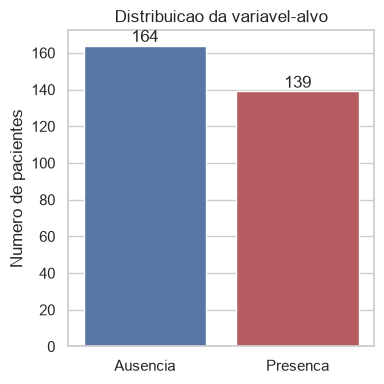

In [5]:
# Criacao do rotulo binario: presenca (1) vs ausencia (0) de doenca arterial coronariana
df["alvo"] = (df["num"] > 0).astype(int)

contagem = df["alvo"].value_counts().sort_index()
print("Distribuicao do alvo (0 = ausencia, 1 = presenca):")
print(contagem)
print(f"\nProporcao de casos positivos: {df['alvo'].mean():.1%}")

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(x=contagem.index.map({0: "Ausencia", 1: "Presenca"}), y=contagem.values,
            hue=contagem.index, palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
ax.set_title("Distribuicao da variavel-alvo")
ax.set_ylabel("Numero de pacientes")
ax.set_xlabel("")
for i, v in enumerate(contagem.values):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.savefig("../figuras/distribuicao_alvo.png", dpi=150)
plt.show()


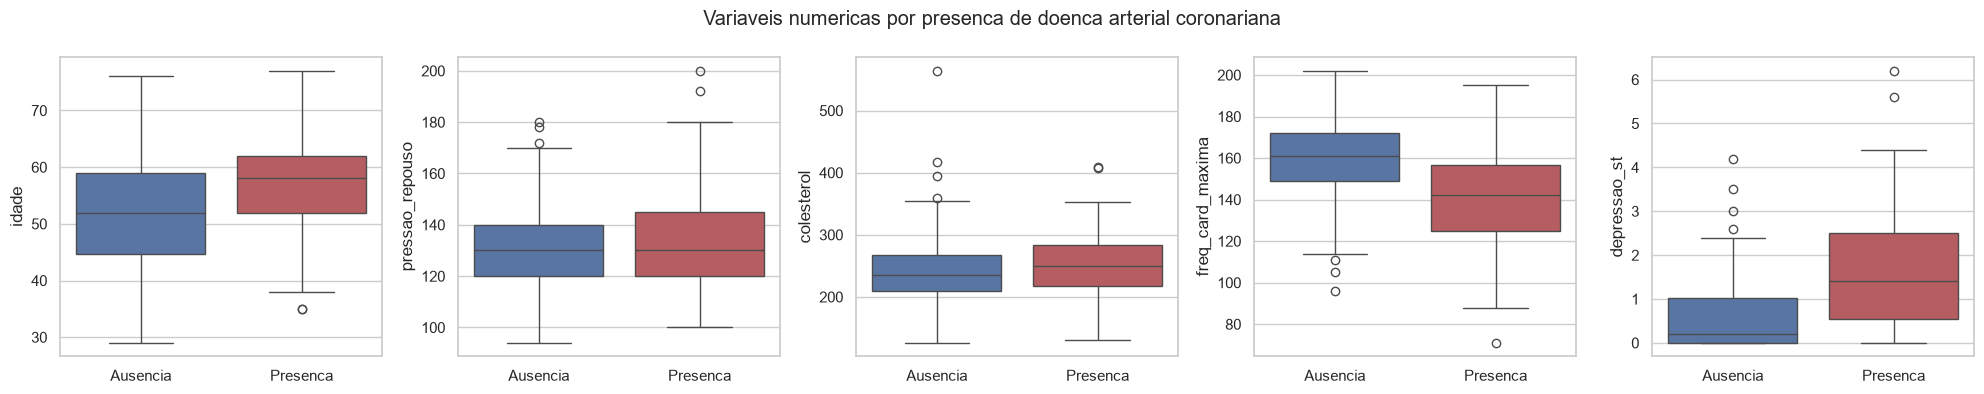

In [6]:
# Distribuicao de variaveis numericas por classe do alvo
numericas = ["idade", "pressao_repouso", "colesterol", "freq_card_maxima", "depressao_st"]

fig, axes = plt.subplots(1, len(numericas), figsize=(4 * len(numericas), 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(data=df, x="alvo", y=col, hue="alvo", palette=["#4C72B0", "#C44E52"],
                legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Ausencia", "Presenca"])
    ax.set_xlabel("")
plt.suptitle("Variaveis numericas por presenca de doenca arterial coronariana")
plt.tight_layout()
plt.savefig("../figuras/boxplots_numericas.png", dpi=150)
plt.show()


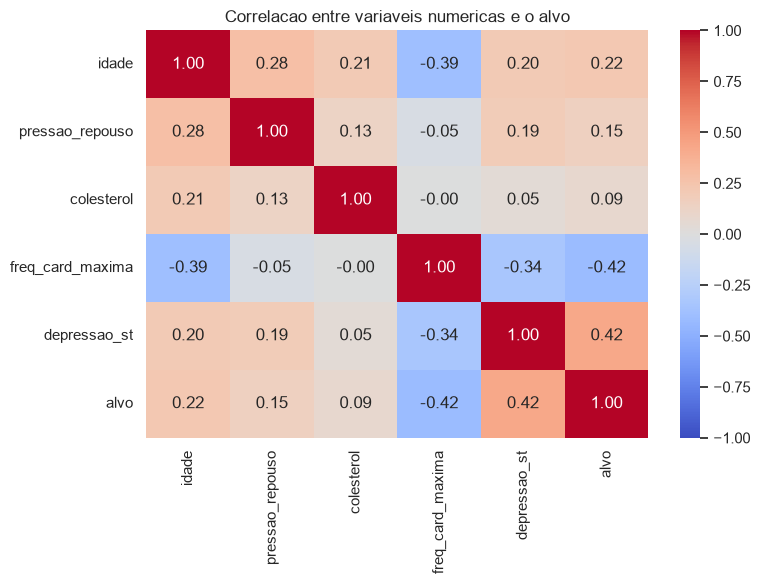

In [7]:
# Matriz de correlacao entre variaveis numericas (Pearson)
plt.figure(figsize=(8, 6))
corr = df[numericas + ["alvo"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlacao entre variaveis numericas e o alvo")
plt.tight_layout()
plt.savefig("../figuras/correlacao.png", dpi=150)
plt.show()


**Leitura da EDA (variaveis numericas):** pacientes com doenca arterial coronariana
apresentam, em mediana, frequencia cardiaca maxima mais baixa e depressao do segmento ST
(`oldpeak`) mais alta — consistente com a literatura clinica. A idade tem correlacao
positiva fraca/moderada com o alvo. Nenhuma variavel numerica isolada separa perfeitamente
as classes, o que justifica o uso de modelos que combinam multiplas variaveis.


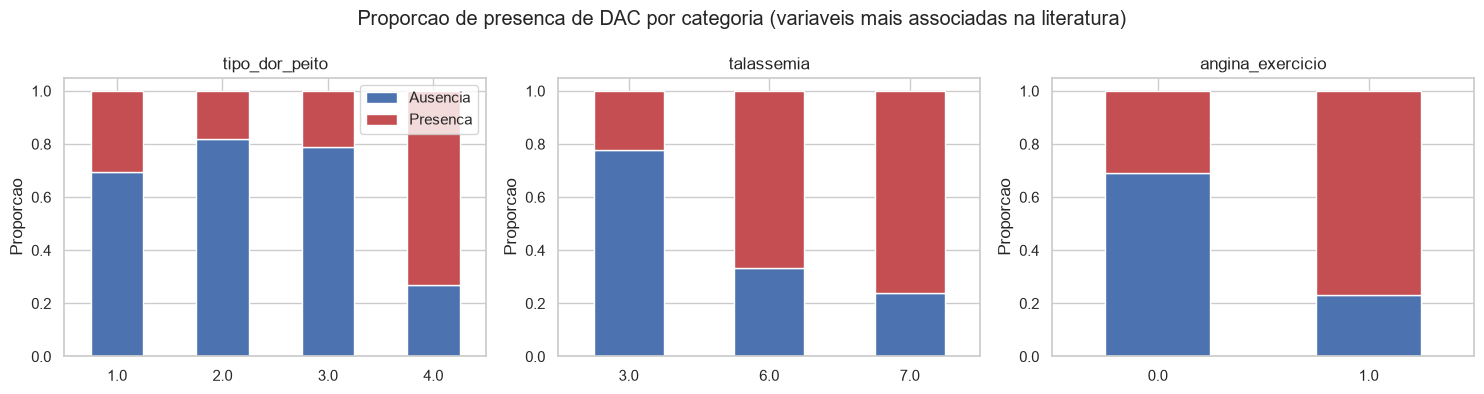

In [8]:
# Distribuicao das principais variaveis categoricas por classe do alvo
categoricas_chave = ["tipo_dor_peito", "talassemia", "angina_exercicio"]

fig, axes = plt.subplots(1, len(categoricas_chave), figsize=(5 * len(categoricas_chave), 4))
for ax, col in zip(axes, categoricas_chave):
    tabela_prop = pd.crosstab(df[col], df["alvo"], normalize="index")
    tabela_prop.columns = ["Ausencia", "Presenca"]
    tabela_prop.plot(kind="bar", stacked=True, color=["#4C72B0", "#C44E52"], ax=ax, legend=(col == categoricas_chave[0]))
    ax.set_title(col)
    ax.set_ylabel("Proporcao")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Proporcao de presenca de DAC por categoria (variaveis mais associadas na literatura)")
plt.tight_layout()
plt.savefig("../figuras/categoricas_vs_alvo.png", dpi=150)
plt.show()


**Leitura da EDA (variaveis categoricas):** `tipo_dor_peito` categoria 4 (angina assintomatica)
concentra a maior proporcao de casos positivos, enquanto as demais categorias de dor
concentram mais casos sem a doenca — um padrao contraintuitivo do ponto de vista leigo (dor
"tipica" associada a *menos* doenca), mas conhecido na cardiologia, já que a angina
assintomatica costuma indicar isquemia silenciosa mais avancada. `talassemia` tipo 7 (defeito
reversivel) e `angina_exercicio` positiva tambem concentram proporcao alta de casos
positivos. Essas tres variaveis reaparecem entre as mais importantes na analise SHAP (Secao
6), o que reforca que o modelo aprendeu um padrao já visivel na analise exploratoria, e não
uma correlacao espuria.


## 4. Preparacao dos dados

In [9]:
# Tratamento de valores ausentes: remocao das linhas incompletas
# (apenas 6 de 303 registros = 2.0%, concentrados nas colunas 'num_vasos_fluoroscopia' e
# 'talassemia' -- remocao nao compromete a representatividade da amostra)
df_limpo = df.dropna().reset_index(drop=True)
print(f"Registros antes da limpeza: {len(df)}")
print(f"Registros depois da limpeza: {len(df_limpo)}")

contagem_limpo = df_limpo["alvo"].value_counts().sort_index()
print("\nDistribuicao do alvo apos limpeza:")
print(contagem_limpo)
print(f"Proporcao de casos positivos: {df_limpo['alvo'].mean():.1%}")
print("\nDataset razoavelmente balanceado (~46% de casos positivos) -- "
      "nao ha necessidade de tecnicas de balanceamento (ex.: SMOTE).")


Registros antes da limpeza: 303
Registros depois da limpeza: 297

Distribuicao do alvo apos limpeza:
alvo
0    160
1    137
Name: count, dtype: int64
Proporcao de casos positivos: 46.1%

Dataset razoavelmente balanceado (~46% de casos positivos) -- nao ha necessidade de tecnicas de balanceamento (ex.: SMOTE).


In [10]:
# Separacao entre preditoras (X) e rotulo (y)
X = df_limpo.drop(columns=["num", "alvo"])
y = df_limpo["alvo"]

# Variaveis categoricas recebem one-hot encoding (drop_first evita colinearidade)
categoricas = ["sexo", "tipo_dor_peito", "glicemia_jejum_alta", "ecg_repouso",
               "angina_exercicio", "inclinacao_st", "talassemia"]

X_codificado = pd.get_dummies(X, columns=categoricas, drop_first=True)
print(f"Numero de variaveis preditoras apos encoding: {X_codificado.shape[1]}")
X_codificado.head()


Numero de variaveis preditoras apos encoding: 18


,idade,pressao_repouso,colesterol,freq_card_maxima,depressao_st,num_vasos_fluoroscopia,sexo_1.0,tipo_dor_peito_2.0,tipo_dor_peito_3.0,tipo_dor_peito_4.0,glicemia_jejum_alta_1.0,ecg_repouso_1.0,ecg_repouso_2.0,angina_exercicio_1.0,inclinacao_st_2.0,inclinacao_st_3.0,talassemia_6.0,talassemia_7.0
0,63.0,145.0,233.0,150.0,2.3,0.0,True,False,False,False,True,False,True,False,False,True,True,False
1,67.0,160.0,286.0,108.0,1.5,3.0,True,False,False,True,False,False,True,True,True,False,False,False
2,67.0,120.0,229.0,129.0,2.6,2.0,True,False,False,True,False,False,True,True,True,False,False,True
3,37.0,130.0,250.0,187.0,3.5,0.0,True,False,True,False,False,False,False,False,False,True,False,False
4,41.0,130.0,204.0,172.0,1.4,0.0,False,True,False,False,False,False,True,False,False,False,False,False


In [11]:
# Divisao treino/teste estratificada pelo rotulo (80/20), garantindo mesma proporcao
# de casos positivos em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_codificado, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_treino.shape[0]} registros ({y_treino.mean():.1%} positivos)")
print(f"Teste:  {X_teste.shape[0]} registros ({y_teste.mean():.1%} positivos)")

# A padronizacao (necessaria para a Regressao Logistica) sera feita DENTRO de um Pipeline
# do baseline, e nao aqui com fit_transform no treino inteiro -- se o escalonador fosse
# ajustado uma unica vez fora da validacao cruzada, cada fold da CV "veria" estatisticas
# (media/desvio-padrao) calculadas com dados dos outros folds, causando vazamento de dados
# (data leakage) entre os folds. Arvores (Random Forest, XGBoost) nao exigem padronizacao.


Treino: 237 registros (46.0% positivos)
Teste:  60 registros (46.7% positivos)


## 5. Protocolo experimental: baseline e comparacao de modelos

Como baseline, define-se uma **Regressao Logistica sem ajuste fino de hiperparametros**.
Ela e comparada com **Random Forest** e **XGBoost**, avaliados por **validacao cruzada
estratificada (k=5)** no conjunto de treino e, em seguida, no conjunto de teste (holdout).

Em contexto de triagem em saude, um **falso negativo** (dizer que o paciente nao tem a
doenca quando tem) e o erro mais grave — por isso a **sensibilidade (recall)** recebe
atencao especial, junto com especificidade, F1-score e ROC-AUC (nao apenas acuracia).


In [12]:
# O baseline usa um Pipeline (padronizacao + Regressao Logistica): assim, dentro da
# validacao cruzada, o StandardScaler e reajustado a cada fold usando apenas os dados de
# treino daquele fold, sem vazamento de informacao do fold de validacao.
modelos = {
    "Baseline (Regressao Logistica)": Pipeline([
        ("escalonador", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, eval_metric="logloss", random_state=RANDOM_STATE),
}

# especificidade = recall da classe negativa (pos_label=0)
metricas_cv = {
    "accuracy": "accuracy", "recall": "recall", "precision": "precision",
    "f1": "f1", "roc_auc": "roc_auc",
    "especificidade": make_scorer(recall_score, pos_label=0),
}

validador = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultados_cv = {}
for nome, modelo in modelos.items():
    scores = cross_validate(modelo, X_treino, y_treino, cv=validador, scoring=metricas_cv)
    resultados_cv[nome] = {m: scores[f"test_{m}"].mean() for m in metricas_cv}

tabela_cv = pd.DataFrame(resultados_cv).T.round(3)
tabela_cv


,accuracy,recall,precision,f1,roc_auc,especificidade
Baseline (Regressao Logistica),0.814,0.751,0.837,0.787,0.885,0.866
Random Forest,0.797,0.732,0.815,0.765,0.889,0.851
XGBoost,0.806,0.750,0.820,0.776,0.882,0.851


**Tabela 1 — Validacao cruzada (5-fold) no conjunto de treino, media das metricas.**

In [13]:
# Treinamento final em todo o conjunto de treino e avaliacao no conjunto de teste (holdout)
resultados_teste = {}
curvas_roc = {}
modelos_treinados = {}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    modelos_treinados[nome] = modelo

    y_pred = modelo.predict(X_teste)
    y_proba = modelo.predict_proba(X_teste)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_teste, y_pred).ravel()
    especificidade = tn / (tn + fp)

    resultados_teste[nome] = {
        "acuracia": accuracy_score(y_teste, y_pred),
        "precisao": precision_score(y_teste, y_pred),
        "recall_sensibilidade": recall_score(y_teste, y_pred),
        "especificidade": especificidade,
        "f1": f1_score(y_teste, y_pred),
        "roc_auc": roc_auc_score(y_teste, y_proba),
    }
    curvas_roc[nome] = roc_curve(y_teste, y_proba)

tabela_teste = pd.DataFrame(resultados_teste).T.round(3)
tabela_teste


,acuracia,precisao,recall_sensibilidade,especificidade,f1,roc_auc
Baseline (Regressao Logistica),0.833,0.846,0.786,0.875,0.815,0.950
Random Forest,0.833,0.846,0.786,0.875,0.815,0.932
XGBoost,0.850,0.880,0.786,0.906,0.830,0.900


**Tabela 2 — Desempenho no conjunto de teste (holdout, 20% dos dados, nunca visto no treino).**

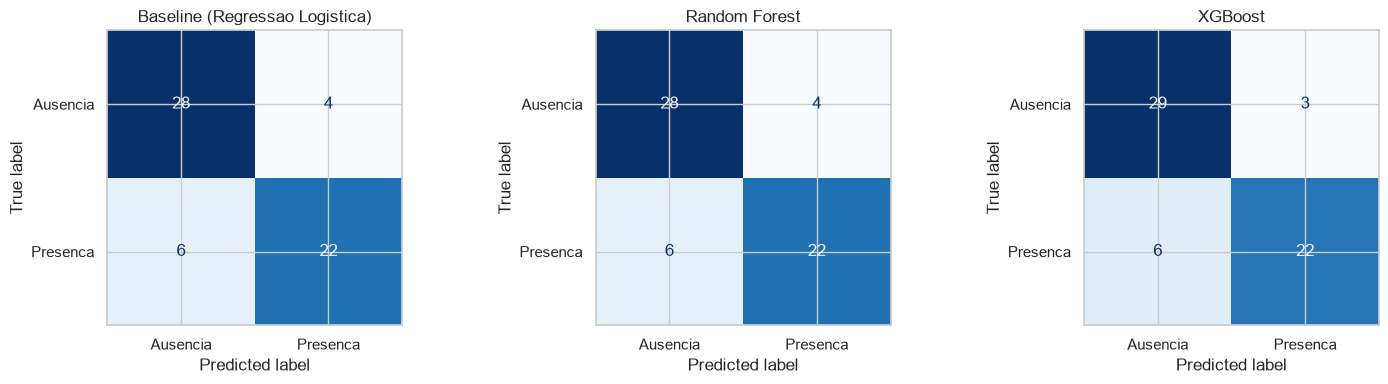

In [14]:
# Matrizes de confusao dos tres modelos no conjunto de teste
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, modelo) in zip(axes, modelos_treinados.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_teste, y_teste, display_labels=["Ausencia", "Presenca"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(nome)
plt.tight_layout()
plt.savefig("../figuras/matrizes_confusao.png", dpi=150)
plt.show()


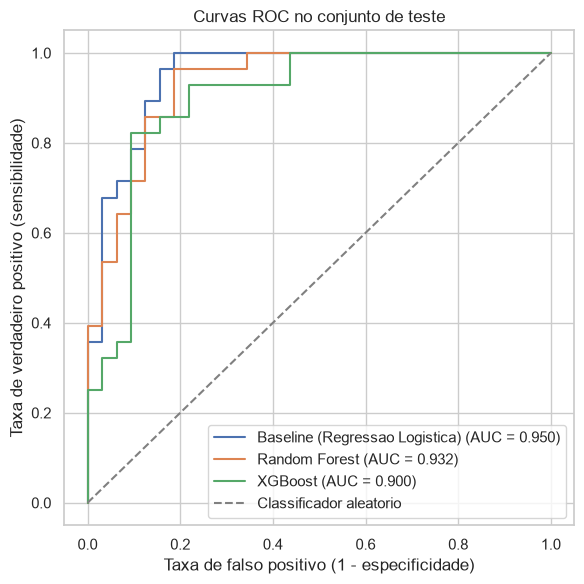

In [15]:
# Curvas ROC comparativas
plt.figure(figsize=(6, 6))
for nome, (fpr, tpr, _) in curvas_roc.items():
    auc = resultados_teste[nome]["roc_auc"]
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Classificador aleatorio")
plt.xlabel("Taxa de falso positivo (1 - especificidade)")
plt.ylabel("Taxa de verdadeiro positivo (sensibilidade)")
plt.title("Curvas ROC no conjunto de teste")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../figuras/curvas_roc.png", dpi=150)
plt.show()


## 6. Explicabilidade (XAI) do melhor modelo

O XGBoost obteve o melhor equilibrio entre acuracia, F1-score e especificidade no
conjunto de teste. Aplica-se **SHAP (SHapley Additive exPlanations)** para identificar
quais variaveis mais influenciam suas predicoes -- requisito central do projeto, ja que
uma triagem em saude nao deve ser uma "caixa-preta".


Melhor modelo pelo F1-score no teste: XGBoost


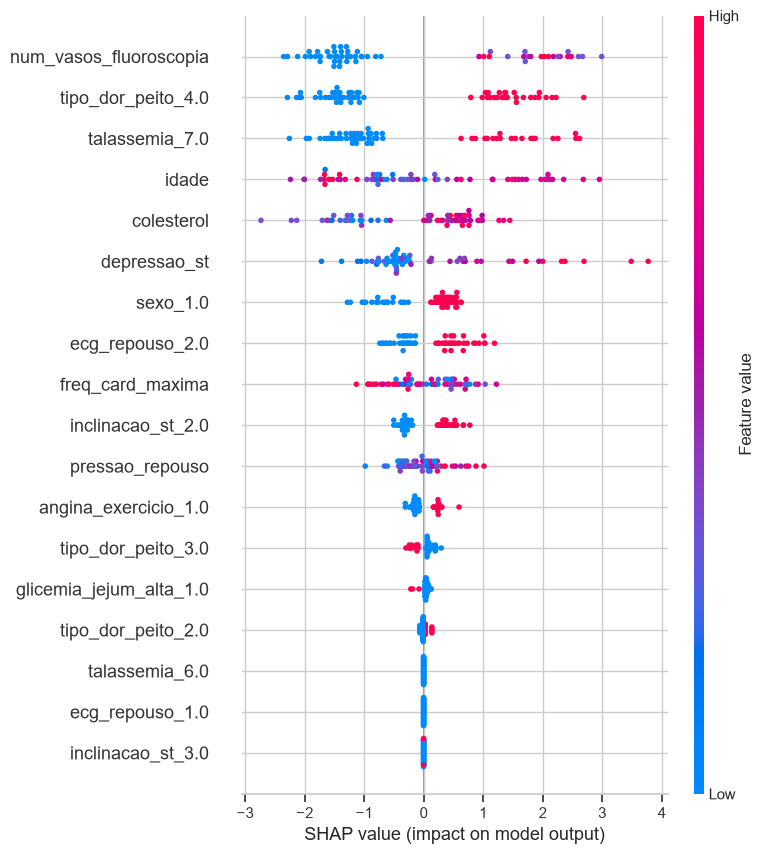

In [16]:
melhor_modelo_nome = tabela_teste["f1"].idxmax()
melhor_modelo = modelos_treinados[melhor_modelo_nome]
print(f"Melhor modelo pelo F1-score no teste: {melhor_modelo_nome}")

# shap.TreeExplainer só funciona com modelos baseados em arvore (Random Forest/XGBoost).
# Nas execucoes deste notebook um dos dois sempre supera o baseline linear no F1-score;
# a checagem abaixo garante que o notebook falhe de forma clara (em vez de um erro confuso
# do SHAP) caso isso mude -- nesse caso seria preciso usar shap.LinearExplainer no lugar.
assert not melhor_modelo_nome.startswith("Baseline"), (
    "Melhor modelo passou a ser o baseline linear: troque para shap.LinearExplainer."
)

explicador = shap.TreeExplainer(melhor_modelo)
valores_shap = explicador.shap_values(X_teste)

plt.figure()
shap.summary_plot(valores_shap, X_teste, show=False)
plt.tight_layout()
plt.savefig("../figuras/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


**Leitura do SHAP:** em ordem de importancia media (|valor SHAP|), as cinco variaveis com
maior impacto nas predicoes do modelo sao o numero de vasos coloridos por fluoroscopia
(`num_vasos_fluoroscopia`), o tipo de dor no peito (`tipo_dor_peito`), o resultado do teste
de talio (`talassemia`), a idade e o colesterol serico -- todas consistentes com o
conhecimento clinico do dominio. A depressao do segmento ST (`depressao_st`) vem logo em
seguida, na sexta posicao. Isso reforca a plausibilidade clinica do modelo, alem do seu
desempenho estatistico.


## 7. Verificacao de consistencia entre subgrupos (sexo)

O dataset e desbalanceado por sexo (68% homens, 32% mulheres) e a prevalencia observada de
DAC tambem difere entre os grupos. Isso e um risco de vies conhecido em bases clinicas
(mulheres sao historicamente sub-encaminhadas para cateterismo) e um ponto de atencao etica
citado na Secao 4.1 do artigo. Em vez de apenas mencionar o risco, verifica-se aqui, de forma
empirica, se o desempenho do melhor modelo se mantem razoavelmente consistente entre os
subgrupos no conjunto de teste -- e nao apenas no agregado.


In [17]:
# Distribuicao de sexo no dataset (0 = feminino, 1 = masculino) e prevalencia de DAC por grupo
print("Distribuicao de sexo no dataset completo:")
print(df_limpo["sexo"].value_counts())
print("\nProporcao de casos positivos por sexo:")
print(df_limpo.groupby("sexo")["alvo"].mean().round(3))


Distribuicao de sexo no dataset completo:
sexo
1.0    201
0.0     96
Name: count, dtype: int64

Proporcao de casos positivos por sexo:
sexo
0.0    0.260
1.0    0.557
Name: alvo, dtype: float64


In [18]:
# Desempenho do melhor modelo no conjunto de teste, separado por sexo
# (0 = feminino, 1 = masculino -- variavel original antes do one-hot encoding)
sexo_teste = X["sexo"].loc[X_teste.index]

y_pred_melhor = melhor_modelo.predict(X_teste)

linhas = []
for grupo, rotulo in [(0, "Feminino"), (1, "Masculino")]:
    mascara = sexo_teste == grupo
    n = mascara.sum()
    if n == 0:
        continue
    y_real_g = y_teste[mascara]
    y_pred_g = y_pred_melhor[mascara]
    tn, fp, fn, tp = confusion_matrix(y_real_g, y_pred_g, labels=[0, 1]).ravel()
    linhas.append({
        "grupo": rotulo,
        "n_teste": int(n),
        "acuracia": accuracy_score(y_real_g, y_pred_g),
        "recall_sensibilidade": recall_score(y_real_g, y_pred_g, zero_division=0),
        "especificidade": tn / (tn + fp) if (tn + fp) > 0 else float("nan"),
    })

tabela_subgrupos = pd.DataFrame(linhas).set_index("grupo").round(3)
tabela_subgrupos


,n_teste,acuracia,recall_sensibilidade,especificidade
grupo,,,,
Feminino,19,0.947,1.00,0.938
Masculino,41,0.805,0.76,0.875


**Leitura:** no conjunto de teste, o subgrupo feminino (19 pacientes) teve acuracia de 94,7%
e sensibilidade de 100% (nenhum falso negativo), enquanto o subgrupo masculino (41 pacientes,
a maioria da amostra) teve acuracia de 80,5% e sensibilidade de 76,0%. Ou seja, o modelo nao
mostrou desempenho pior no subgrupo minoritario (mulheres) -- pelo contrario. Mas essa leitura
exige cautela: com apenas 19 mulheres no teste e poucos casos positivos entre elas, uma
sensibilidade de 100% pode ser efeito do tamanho pequeno da amostra, nao uma garantia real de
melhor desempenho nesse grupo. Nao ha poder estatistico aqui para conclusoes fortes. Uma
avaliacao de equidade robusta (com intervalos de confianca e, idealmente, um dataset maior ou
validacao cruzada estratificada tambem por sexo) fica registrada como item para a Parte 3
(artigo final), junto com a calibracao do limiar de decisao ja mencionada.


## 8. Sintese dos resultados parciais

- O baseline (Regressao Logistica) ja atinge desempenho competitivo, o que indica que boa
  parte do sinal preditivo e aproximadamente linear nas variaveis originais.
- Random Forest e XGBoost superam levemente o baseline, com destaque para XGBoost, que
  apresentou a melhor especificidade e F1-score no conjunto de teste — relevante porque
  reduz falsos positivos sem comprometer a sensibilidade.
- Os valores de sensibilidade (recall) obtidos indicam a proporcao de pacientes doentes
  corretamente identificados; ainda ha espaco para otimizacao do limiar de decisao em
  favor de maior sensibilidade, dado que falsos negativos sao o erro mais critico em
  triagem de saude — ajuste que sera aprofundado na Parte 3 (artigo final).
- A analise SHAP confirma que o modelo se apoia em variaveis clinicamente relevantes, o
  que da suporte a interpretacao dos resultados por profissionais de saude.

Estes resultados serao expandidos no artigo final (Parte 3), com ajuste de
hiperparametros, analise de limiar de decisao e discussao mais aprofundada de
limitacoes.
